# Лабораторная работа №4 — исследовательский анализ и визуализация данных

**Исходный набор:** `../lab01/dataset/cat` и `../lab01/dataset/dog`. 

Для каждого пункта есть отдельный модуль Python с функциями. Notebook дополняет скрипты пошаговыми пояснениями и решениями

### Результат

- исходный CSV со столбцами `class_name`, `absolute_path`;
- числовые метки `cat = 0`, `dog = 1`;
- высота, ширина и число каналов каждого изображения;
- описательная статистика, таблица баланса и график распределения классов;
- фильтрация по классу и размерам;
- количество пикселей и статистику `min / max / mean` по классам;
- несколько примеров изображений;
- три массива гистограмм OpenCV для случайного изображения класса и их графики.

## Подготовка — импорты и пути

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from config import (
    PROJECT_DIR, SOURCE_DATASET_DIR, ANNOTATION_CSV, NORMALIZED_CSV,
    LABELED_CSV, DIMENSIONS_CSV, ANALYSIS_CSV, FILTERED_CLASS_CSV,
    FILTERED_DIMENSIONS_CSV, DESCRIBE_CSV, CLASS_COUNTS_CSV,
    PIXEL_STATS_CSV, REPORTS_DIR, PLOTS_DIR, CLASS_TO_LABEL,
)

print("Корень проекта:", PROJECT_DIR)
print("Источник изображений:", SOURCE_DATASET_DIR)
print("Каталог найден:", SOURCE_DATASET_DIR.is_dir())
print("Словарь числовых меток:", CLASS_TO_LABEL)

Корень проекта: F:\NTSE\lab04
Источник изображений: F:\NTSE\lab01\dataset
Каталог найден: True
Словарь числовых меток: {'cat': 0, 'dog': 1}


## Формирование исходного DataFrame и CSV-аннотации

Таблица содержит две колонки: `class_name` — текстовая метка класса и `absolute_path` — абсолютный путь к изображению. Список файлов собирается автоматически из подпапок датасета.

In [2]:
from dataset_annotation import create_annotation_dataframe, save_annotation

annotation_df = create_annotation_dataframe(SOURCE_DATASET_DIR)
save_annotation(annotation_df, ANNOTATION_CSV)

display(annotation_df.head())
print("Размер DataFrame:", annotation_df.shape)
print("Колонки:", list(annotation_df.columns))
display(annotation_df["class_name"].value_counts().rename_axis("class_name").to_frame("count"))

,class_name,absolute_path
0,cat,F:\NTSE\lab01\dataset\cat\0000.jpg
1,cat,F:\NTSE\lab01\dataset\cat\0001.jpg
2,cat,F:\NTSE\lab01\dataset\cat\0002.jpg
3,cat,F:\NTSE\lab01\dataset\cat\0003.jpg
4,cat,F:\NTSE\lab01\dataset\cat\0004.jpg


Размер DataFrame: (2307, 2)
Колонки: ['class_name', 'absolute_path']


,count
class_name,
cat,1200
dog,1107


## Нормализация имён колонок

Названия уже на английском, в нижнем регистре и с `_` вместо пробелов, но функция реализована. В текущем DataFrame ожидаются `class_name` и `absolute_path`.

In [3]:
from column_names import normalize_column_names, save_normalized_dataframe

normalized_df = normalize_column_names(annotation_df)
save_normalized_dataframe(normalized_df, NORMALIZED_CSV)
assert list(normalized_df.columns) == ["class_name", "absolute_path"]
print("Нормализованные колонки:", list(normalized_df.columns))
display(normalized_df.head())

Нормализованные колонки: ['class_name', 'absolute_path']


,class_name,absolute_path
0,cat,F:\NTSE\lab01\dataset\cat\0000.jpg
1,cat,F:\NTSE\lab01\dataset\cat\0001.jpg
2,cat,F:\NTSE\lab01\dataset\cat\0002.jpg
3,cat,F:\NTSE\lab01\dataset\cat\0003.jpg
4,cat,F:\NTSE\lab01\dataset\cat\0004.jpg


## Добавление числовой метки класса

Используется словарь: `cat → 0`, `dog → 1`. Новая колонка называется `class_label`. Текстовая `class_name` сохраняется: так проще читать таблицы и подписывать графики.

In [4]:
from class_labels import add_numeric_class_labels, save_labeled_dataframe

labeled_df = add_numeric_class_labels(normalized_df)
save_labeled_dataframe(labeled_df, LABELED_CSV)
display(labeled_df[["class_name", "class_label"]].drop_duplicates().sort_values("class_label"))
print(labeled_df["class_label"].value_counts().sort_index())

,class_name,class_label
0,cat,0
1200,dog,1


class_label
0    1200
1    1107
Name: count, dtype: int64


## Получение высоты, ширины и глубины

OpenCV возвращает изображение как массив. Высота и ширина берутся из первых двух измерений `shape`; глубина в этой работе означает число каналов. Для обычного цветного изображения их три, а изображение с альфа-каналом может иметь четыре.

In [5]:
from image_metadata import add_image_dimensions, save_dimensions_dataframe

dimensions_df = add_image_dimensions(labeled_df)
save_dimensions_dataframe(dimensions_df, DIMENSIONS_CSV)
display(dimensions_df.head())
print("Размер таблицы:", dimensions_df.shape)
print("Колонки:", list(dimensions_df.columns))

,class_name,absolute_path,class_label,height,width,channels
0,cat,F:\NTSE\lab01\dataset\cat\0000.jpg,0,1440,2560,3
1,cat,F:\NTSE\lab01\dataset\cat\0001.jpg,0,720,1280,3
2,cat,F:\NTSE\lab01\dataset\cat\0002.jpg,0,800,1200,3
3,cat,F:\NTSE\lab01\dataset\cat\0003.jpg,0,720,1280,3
4,cat,F:\NTSE\lab01\dataset\cat\0004.jpg,0,720,1280,3


Размер таблицы: (2307, 6)
Колонки: ['class_name', 'absolute_path', 'class_label', 'height', 'width', 'channels']


## Описательная статистика, распределение и баланс

`describe()` показывает количество наблюдений, среднее, стандартное отклонение, минимум, квартили и максимум. Для баланса считаем изображения по классам. Датасет сбалансирован по количеству, если число изображений `cat` и `dog` совпадает.

,width,height,channels,class_label
count,2307.000000,2307.000000,2307.0,2307.000000
mean,1665.475943,1241.734720,3.0,0.479844
std,928.770430,746.066318,0.0,0.499702
min,706.000000,600.000000,3.0,0.000000
25%,1200.000000,800.000000,3.0,0.000000
50%,1332.000000,1067.000000,3.0,0.000000
75%,1749.000000,1363.500000,3.0,1.000000
max,9001.000000,6016.000000,3.0,1.000000


,class_name,class_label,count,share_percent
0,cat,0,1200,52.015605
1,dog,1,1107,47.984395


Сбалансирован: False


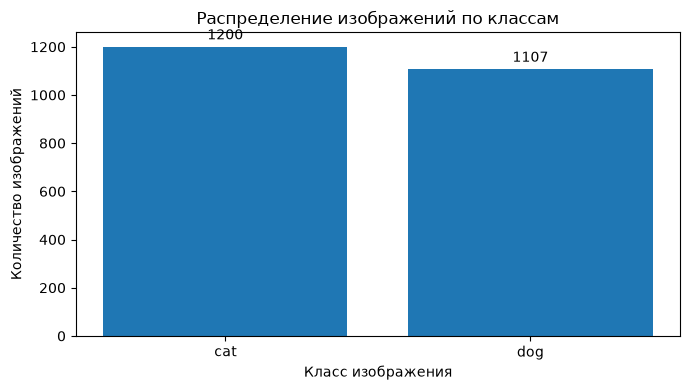

In [6]:
from data_statistics import (
    get_descriptive_statistics, get_class_counts,
    is_dataset_balanced, plot_class_distribution, save_statistics,
)

statistics_df = get_descriptive_statistics(dimensions_df)
class_counts_df = get_class_counts(dimensions_df)
save_statistics(dimensions_df)

display(statistics_df)
display(class_counts_df)
print("Сбалансирован:", is_dataset_balanced(dimensions_df))
plot_class_distribution(dimensions_df)

## Фильтрация по классу

Функция возвращает отдельный DataFrame только с выбранной меткой. Можно передать текстовый класс (`"cat"`) либо числовую метку (`0`). Исходная таблица при этом не изменяется.

In [7]:
from class_filter import filter_by_class

cats_df = filter_by_class(dimensions_df, "cat")
dogs_df = filter_by_class(dimensions_df, "dog")
filtered_by_label_zero = filter_by_class(dimensions_df, 0)

print("Изображений кошек:", len(cats_df))
print("Изображений собак:", len(dogs_df))
print("Изображений с меткой 0:", len(filtered_by_label_zero))
display(cats_df.head())
cats_df.to_csv(FILTERED_CLASS_CSV, index=False, encoding="utf-8-sig")

Изображений кошек: 1200
Изображений собак: 1107
Изображений с меткой 0: 1200


,class_name,absolute_path,class_label,height,width,channels
0,cat,F:\NTSE\lab01\dataset\cat\0000.jpg,0,1440,2560,3
1,cat,F:\NTSE\lab01\dataset\cat\0001.jpg,0,720,1280,3
2,cat,F:\NTSE\lab01\dataset\cat\0002.jpg,0,800,1200,3
3,cat,F:\NTSE\lab01\dataset\cat\0003.jpg,0,720,1280,3
4,cat,F:\NTSE\lab01\dataset\cat\0004.jpg,0,720,1280,3


## Фильтрация по классу и размерам

Остаются строки, где одновременно выполняются три условия: выбранный класс, `width <= max_width` и `height <= max_height`. Числа в примере можно менять и повторно запускать ячейку.

In [8]:
from dimension_filter import filter_by_class_and_dimensions

MAX_WIDTH = 800
MAX_HEIGHT = 600
small_cats_df = filter_by_class_and_dimensions(
    dimensions_df,
    class_label="cat",
    max_width=MAX_WIDTH,
    max_height=MAX_HEIGHT,
)

print(f"Кошек не больше {MAX_WIDTH}×{MAX_HEIGHT}:", len(small_cats_df))
display(small_cats_df[["class_name", "width", "height", "absolute_path"]].head())
assert (small_cats_df["width"] <= MAX_WIDTH).all()
assert (small_cats_df["height"] <= MAX_HEIGHT).all()
assert (small_cats_df["class_name"] == "cat").all()
small_cats_df.to_csv(FILTERED_DIMENSIONS_CSV, index=False, encoding="utf-8-sig")

Кошек не больше 800×600: 0


,class_name,width,height,absolute_path


## Количество пикселей, группировка и примеры изображений

Количество пикселей равно `width * height`; количество цветовых каналов в этот показатель не умножается. Затем вычислим минимальное, максимальное и среднее число пикселей для каждого класса и визуально посмотрим пять случайных изображений.

In [9]:
from pixel_statistics import add_pixel_count, group_pixel_statistics, plot_sample_images

analysis_df = add_pixel_count(dimensions_df)
pixel_stats_df = group_pixel_statistics(analysis_df)
analysis_df.to_csv(ANALYSIS_CSV, index=False, encoding="utf-8-sig")
pixel_stats_df.to_csv(PIXEL_STATS_CSV, encoding="utf-8-sig")

display(analysis_df[["class_name", "width", "height", "pixel_count"]].head())
display(pixel_stats_df)

,class_name,width,height,pixel_count
0,cat,2560,1440,3686400
1,cat,1280,720,921600
2,cat,1200,800,960000
3,cat,1280,720,921600
4,cat,1280,720,921600


,minimum_pixels,maximum_pixels,average_pixels
class_name,,,
cat,518400,43707606,2.728091e+06
dog,518400,54006000,2.515062e+06


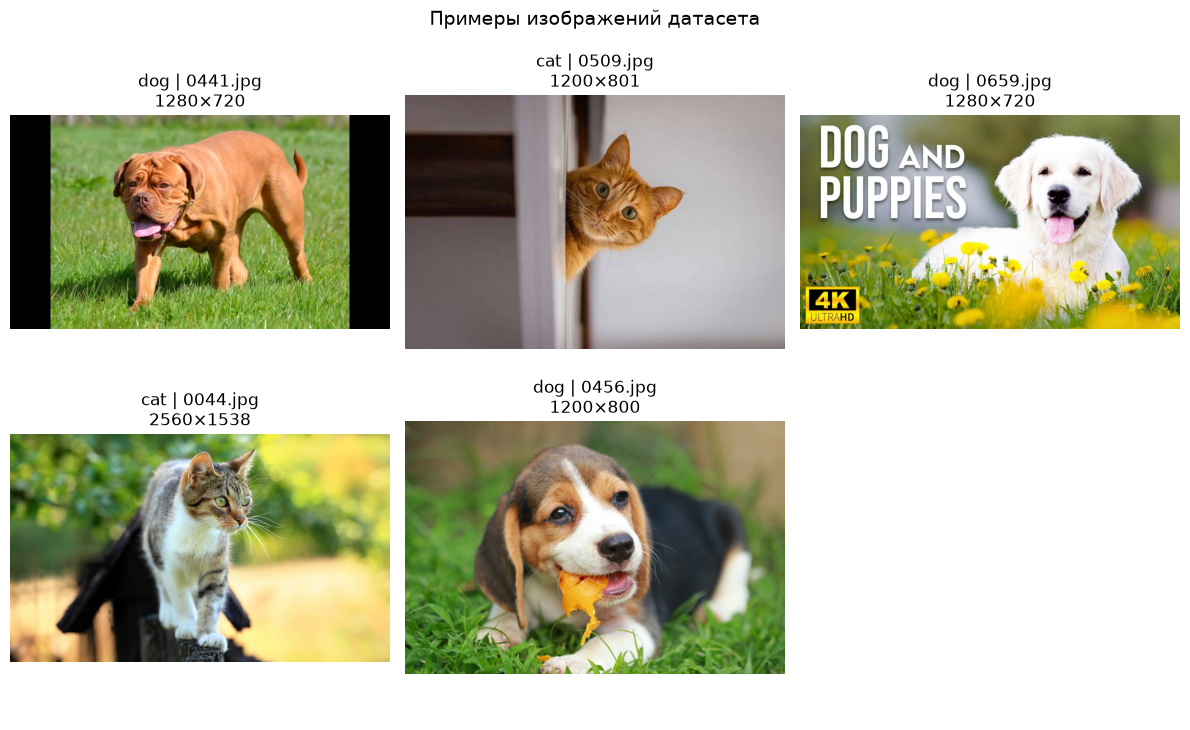

In [10]:
plot_sample_images(analysis_df, sample_size=5, random_state=42)

## Гистограммы через OpenCV

Для выбранного класса функция случайно перебирает его изображения, выбирает первое успешно прочитанное и через `cv2.calcHist()` строит три массива по 256 значений интенсивности. OpenCV читает цветные картинки в порядке BGR: синий, зелёный, красный.

In [11]:
from image_histogram import calculate_random_image_histogram, save_histogram_arrays

cat_histograms = calculate_random_image_histogram(analysis_df, "cat")
dog_histograms = calculate_random_image_histogram(analysis_df, "dog")

print("Гистограммы cat:", [array.shape for array in cat_histograms])
print("Гистограммы dog:", [array.shape for array in dog_histograms])
print("Сохранённые массивы:", save_histogram_arrays(cat_histograms, "cat"), save_histogram_arrays(dog_histograms, "dog"))

Гистограммы cat: [(256,), (256,), (256,)]
Гистограммы dog: [(256,), (256,), (256,)]
Сохранённые массивы: F:\NTSE\lab04\output\reports\cat_histograms.npz F:\NTSE\lab04\output\reports\dog_histograms.npz


## Визуализация трёх гистограмм

Ось X показывает интенсивность цвета от 0 до 255, ось Y — количество пикселей с такой интенсивностью. У каждого канала есть подпись в легенде.

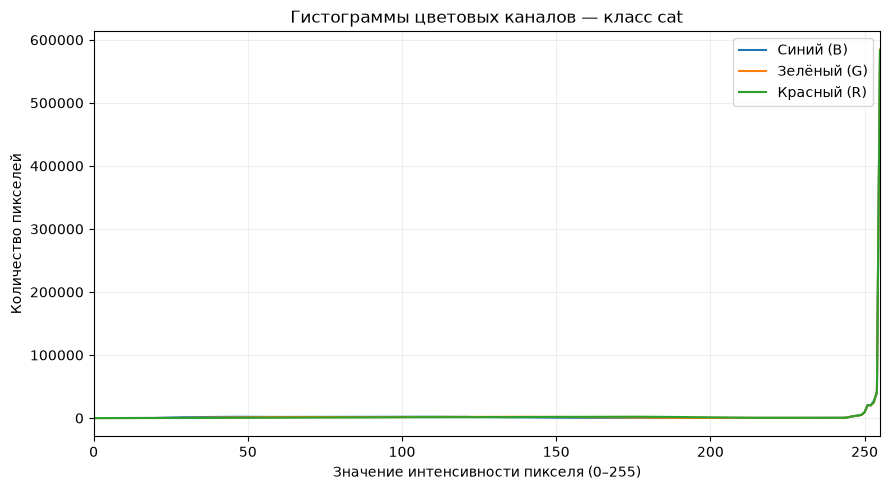

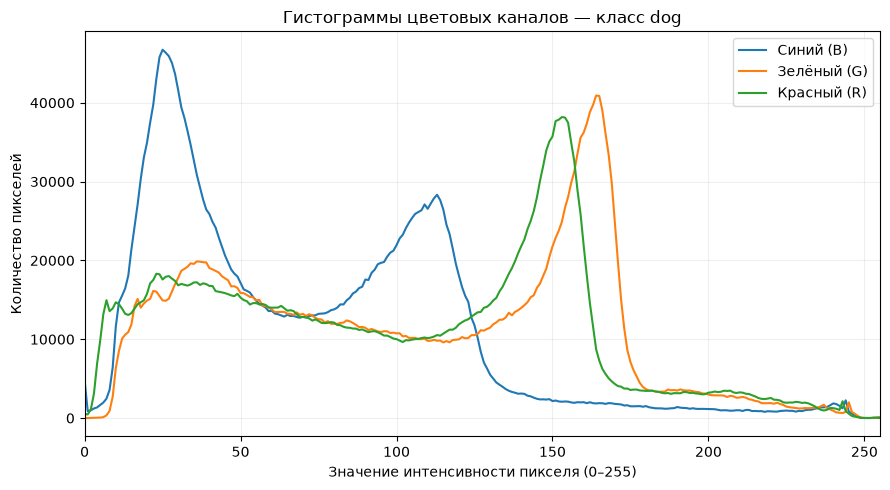

In [12]:
from plot_histograms import plot_color_histograms

plot_color_histograms(cat_histograms, "cat")
plot_color_histograms(dog_histograms, "dog")

## Финальная проверка результата

Проверим обязательные колонки и посмотрим, куда сохранены CSV, сводная статистика и графики.

In [13]:
required_columns = {
    "class_name", "absolute_path", "class_label",
    "height", "width", "channels", "pixel_count",
}
assert required_columns.issubset(analysis_df.columns)
assert analysis_df["class_label"].notna().all()
assert analysis_df[["height", "width", "channels", "pixel_count"]].notna().all().all()

print("Количество исходных изображений:", len(annotation_df))
print("Баланс классов:", "да" if is_dataset_balanced(analysis_df) else "нет")
print("Исходная аннотация:", ANNOTATION_CSV)
print("Итоговая таблица:", ANALYSIS_CSV)
print("Сводная статистика:", REPORTS_DIR)
print("Графики:", PLOTS_DIR)

Количество исходных изображений: 2307
Баланс классов: нет
Исходная аннотация: F:\NTSE\lab04\annotations\dataset_annotation.csv
Итоговая таблица: F:\NTSE\lab04\annotations\pixel_analysis.csv
Сводная статистика: F:\NTSE\lab04\output\reports
Графики: F:\NTSE\lab04\output\plots
